# Major Project: UncertaCat v6_1.0 - In-Domain Dual-Architecture Benchmark (288x288)

**Scope & Clinical Paradigm:**
This notebook implements **Tier 1 (In-Domain Training & Zero-Shot External Evaluation)** for project **UncertaCat**.
- **Training Cohort**: Strictly In-Domain internal datasets only (`train`, `val`, `internal_test` from ODIR-5K, EyeDiseases, CSDI, CataractDataset). **Zero images from external datasets (RFMiD) are seen during training or validation.**
- **Evaluation Paradigm**: Out-of-the-box Zero-Shot deployment on completely unseen external clinic data (`ext_holdout` from RFMiD, India).
- **Architecture Benchmark (Option 2)**: Dual-Architecture Heterogeneous Ensemble (**DenseNet-121 + ConvNeXt-Tiny**) at **288x288** spatial resolution.
- **Experimental Rigor**: Full 3-seed replication (`[42, 7, 2024]`), plain R0 loss formulation, Green-channel CLAHE contrast enhancement, and Platt scaling (logistic calibration).


In [1]:
# Cell 1: Environment Setup, Paths, & Deterministic Seeds
import os
import sys
import re
import random
import time
import json
import math
import copy
from pathlib import Path
from collections import defaultdict

import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import densenet121, DenseNet121_Weights
import timm

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    accuracy_score, confusion_matrix, classification_report,
    brier_score_loss, log_loss
)
from scipy.stats import mannwhitneyu

# Ensure reproducibility
GLOBAL_SEED = 42
SEEDS = [42, 7, 2024]

def set_seed(seed=GLOBAL_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(GLOBAL_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DRIVE_ROOT = r"c:\Users\umari\Major Project\Major Project New"
DATA_DIR = os.path.join(DRIVE_ROOT, 'preprocessed images')
IMAGES_DIR = os.path.join(DATA_DIR, 'images')
METADATA_PATH = os.path.join(DATA_DIR, 'metadata_v3.csv')

MODELS_V6_DIR = os.path.join(DRIVE_ROOT, 'models_v6', 'models_v6_1.0')
RESULTS_V6_DIR = os.path.join(DRIVE_ROOT, 'evaluation_results_v6')

os.makedirs(MODELS_V6_DIR, exist_ok=True)
os.makedirs(RESULTS_V6_DIR, exist_ok=True)

print("=" * 70)
print("UNCERTACAT v6_1.0 SYSTEM & HARDWARE AUDIT")
print("=" * 70)
print(f"   Python Version:        {sys.version.split()[0]}")
print(f"   PyTorch Version:       {torch.__version__}")
print(f"   Torchvision Version:   {torchvision.__version__}")
print(f"   Timm Version:          {timm.__version__}")
print(f"   Compute Device:        {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
if torch.cuda.is_available():
    print(f"   Total GPU VRAM:        {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"   Models Save Path:      {MODELS_V6_DIR}")
print(f"   Results Save Path:     {RESULTS_V6_DIR}")
print("[CHECK] System initialized.")


C:\Users\umari\.venv_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UNCERTACAT v6_1.0 SYSTEM & HARDWARE AUDIT
   Python Version:        3.12.7
   PyTorch Version:       2.6.0+cu124
   Torchvision Version:   0.21.0+cu124
   Timm Version:          1.0.30
   Compute Device:        cuda (NVIDIA GeForce RTX 2050)
   Total GPU VRAM:        4.29 GB
   Models Save Path:      c:\Users\umari\Major Project\Major Project New\models_v6\models_v6_1.0
   Results Save Path:     c:\Users\umari\Major Project\Major Project New\evaluation_results_v6
[CHECK] System initialized.


In [2]:
# Cell 2: Metadata Ingestion, Split Isolation & Strict Zero-Leakage Checks
df_all = pd.read_csv(METADATA_PATH)
print(f"[INFO] Loaded metadata: {len(df_all)} total scans.")

def extract_source_name(fn):
    fn = str(fn)
    for src in ['ODIR-5K', 'EyeDiseases', 'RFMiD', 'CataractDataset', 'CSDI']:
        if src in fn:
            return src
    return 'Unknown'

if 'source_dataset' not in df_all.columns:
    df_all['source_dataset'] = df_all['processed_filename'].apply(extract_source_name)

def extract_robust_patient_key(row):
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = os.path.basename(str(row.get('absolute_path', '')))
    stem = Path(fn).stem
    source = 'unknown'
    for src in ['ODIR-5K', 'EyeDiseases', 'RFMiD', 'CataractDataset', 'CSDI']:
        if src in stem:
            source = src
            break
    cleaned = re.sub(r'^(ODIR-5K|EyeDiseases|RFMiD|CataractDataset|CSDI)_?', '', stem)
    cleaned = re.sub(r'^(train|val|test|internal_test|external_test)_?', '', cleaned)
    cleaned = re.sub(r'^(cataract|normal)_?', '', cleaned)
    match_eye = re.search(r'(\d+)[_\-\.](left|right|os|od|l|r)', cleaned, re.IGNORECASE)
    if match_eye:
        return f"{source}_pt_{match_eye.group(1)}"
    match_num = re.search(r'(\d+)', cleaned)
    if match_num:
        return f"{source}_pt_{match_num.group(1)}"
    raw_pid = str(row.get('patient_id', ''))
    if raw_pid and raw_pid != 'nan' and raw_pid != 'unknown':
        return f"{source}_{raw_pid}"
    return f"{source}_{cleaned}"

if 'robust_group_key' not in df_all.columns:
    df_all['robust_group_key'] = df_all.apply(extract_robust_patient_key, axis=1)

df_tr = df_all[df_all['split'] == 'train'].reset_index(drop=True)
df_va = df_all[df_all['split'] == 'val'].reset_index(drop=True)
df_te = df_all[df_all['split'] == 'internal_test'].reset_index(drop=True)
df_ad = df_all[df_all['split'] == 'ext_adapt'].reset_index(drop=True)
df_ho = df_all[df_all['split'] == 'ext_holdout'].reset_index(drop=True)

# Strict Assertions: Zero external data in v6_1.0 training
assert 'RFMiD' not in df_tr['source_dataset'].unique(), "ERROR: External dataset found in Train set!"
assert 'RFMiD' not in df_va['source_dataset'].unique(), "ERROR: External dataset found in Val set!"
assert 'RFMiD' not in df_te['source_dataset'].unique(), "ERROR: External dataset found in Internal Test set!"

# Patient Overlap Assertions
tr_keys = set(df_tr['robust_group_key'])
va_keys = set(df_va['robust_group_key'])
te_keys = set(df_te['robust_group_key'])
ho_keys = set(df_ho['robust_group_key'])

assert len(tr_keys & va_keys) == 0, "Patient leakage: Train & Val share patients!"
assert len(tr_keys & te_keys) == 0, "Patient leakage: Train & Internal Test share patients!"
assert len(tr_keys & ho_keys) == 0, "Patient leakage: Train & External Holdout share patients!"
assert len(va_keys & ho_keys) == 0, "Patient leakage: Val & External Holdout share patients!"

print("=" * 70)
print("SPLIT DISTRIBUTION & LEAKAGE VERIFICATION (v6_1.0)")
print("=" * 70)
for s_name, sub in [('Train (Internal)', df_tr), ('Val (Internal)', df_va), 
                    ('Internal Test', df_te), ('External Holdout (Zero-Shot)', df_ho)]:
    pos = (sub['label'] == 1).sum()
    neg = (sub['label'] == 0).sum()
    srcs = dict(sub['source_dataset'].value_counts())
    print(f"   {s_name:28s}: {len(sub):4d} scans | Normal: {neg:4d} | Cataract: {pos:4d} | Prev: {pos/len(sub)*100:4.1f}% | Sources: {srcs}")

print("\n[CHECK] Zero patient leakage verified across all split boundaries.")
print("[CHECK] Strict in-domain isolation confirmed: NO RFMiD data in training or validation.")


[INFO] Loaded metadata: 4622 total scans.
SPLIT DISTRIBUTION & LEAKAGE VERIFICATION (v6_1.0)
   Train (Internal)            : 2667 scans | Normal: 1802 | Cataract:  865 | Prev: 32.4% | Sources: {'ODIR-5K': np.int64(1330), 'EyeDiseases': np.int64(1077), 'CataractDataset': np.int64(152), 'CSDI': np.int64(108)}
   Val (Internal)              :  573 scans | Normal:  395 | Cataract:  178 | Prev: 31.1% | Sources: {'ODIR-5K': np.int64(289), 'EyeDiseases': np.int64(244), 'CataractDataset': np.int64(27), 'CSDI': np.int64(13)}
   Internal Test               :  569 scans | Normal:  370 | Cataract:  199 | Prev: 35.0% | Sources: {'ODIR-5K': np.int64(290), 'EyeDiseases': np.int64(243), 'CataractDataset': np.int64(24), 'CSDI': np.int64(12)}
   External Holdout (Zero-Shot):  407 scans | Normal:  225 | Cataract:  182 | Prev: 44.7% | Sources: {'RFMiD': np.int64(407)}

[CHECK] Zero patient leakage verified across all split boundaries.
[CHECK] Strict in-domain isolation confirmed: NO RFMiD data in trainin

In [3]:
# Cell 3: Circular FOV, Green-Channel CLAHE & Master 288x288 RAM Cache
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]
TARGET_SIZE = 288

def resolve_image_path(row):
    p = str(row.get('absolute_path', ''))
    if p and os.path.exists(p):
        return p
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = str(row.get('filename', ''))
    if fn:
        candidates = [
            os.path.join(IMAGES_DIR, fn),
            os.path.join(DATA_DIR, fn),
            os.path.join(DRIVE_ROOT, 'images', fn),
            os.path.join('.', 'images', fn),
            os.path.join('.', 'preprocessed images', 'images', fn)
        ]
        for c in candidates:
            if os.path.exists(c):
                return c
    return None

clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_fundus_288(img_rgb):
    if img_rgb is None or img_rgb.size == 0:
        return np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
    
    # 1. Circular FOV crop
    gray = img_rgb[:, :, 1]
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        (x, y), radius = cv2.minEnclosingCircle(c)
        center = (int(x), int(y))
        radius = int(radius)
        h, w, _ = img_rgb.shape
        x1 = max(0, center[0] - radius)
        y1 = max(0, center[1] - radius)
        x2 = min(w, center[0] + radius)
        y2 = min(h, center[1] + radius)
        crop = img_rgb[y1:y2, x1:x2]
    else:
        crop = img_rgb
        
    crop_resized = cv2.resize(crop, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_AREA)
    
    # 2. Ben-Graham Illumination Filtering
    blur = cv2.GaussianBlur(crop_resized, (0, 0), 10)
    bg_norm = cv2.addWeighted(crop_resized, 4, blur, -4, 128)
    
    # 3. Green-Channel CLAHE (accentuates cataract media clouding & retinal vessel edges)
    bg_norm[:, :, 1] = clahe_op.apply(bg_norm[:, :, 1])
    
    # 4. Circular Mask
    mask = np.zeros((TARGET_SIZE, TARGET_SIZE), dtype=np.uint8)
    cv2.circle(mask, (TARGET_SIZE // 2, TARGET_SIZE // 2), TARGET_SIZE // 2, 255, -1)
    return cv2.bitwise_and(bg_norm, bg_norm, mask=mask)

GLOBAL_RAM_CACHE_288 = {}

print(f"[INFO] Populating Master RAM Cache at {TARGET_SIZE}x{TARGET_SIZE} uint8 for {len(df_all)} scans...")
t0_cache = time.time()
missing_cnt = 0

for _, row in tqdm(df_all.iterrows(), total=len(df_all), desc=f"Caching Scans in RAM ({TARGET_SIZE}x{TARGET_SIZE})"):
    fn = str(row.get('processed_filename', ''))
    if not fn or fn == 'nan':
        fn = str(row.get('filename', ''))
    p = resolve_image_path(row)
    if p and os.path.exists(p):
        img_bgr = cv2.imread(p)
        if img_bgr is not None:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            GLOBAL_RAM_CACHE_288[fn] = preprocess_fundus_288(img_rgb)
        else:
            GLOBAL_RAM_CACHE_288[fn] = np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
            missing_cnt += 1
    else:
        GLOBAL_RAM_CACHE_288[fn] = np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8)
        missing_cnt += 1

dur_cache = time.time() - t0_cache
ram_mb = (len(GLOBAL_RAM_CACHE_288) * TARGET_SIZE * TARGET_SIZE * 3) / (1024 * 1024)
print(f"[SUCCESS] Master RAM Cache ready: {len(GLOBAL_RAM_CACHE_288)} scans loaded in {dur_cache:.1f}s.")
print(f"          RAM used: {ram_mb:.1f} MB (out of system RAM). Missing fallback: {missing_cnt}.")


[INFO] Populating Master RAM Cache at 288x288 uint8 for 4622 scans...


Caching Scans in RAM (288x288):   0%|          | 0/4622 [00:00<?, ?it/s]

Caching Scans in RAM (288x288):   0%|          | 6/4622 [00:00<01:21, 56.88it/s]

Caching Scans in RAM (288x288):   0%|          | 19/4622 [00:00<00:48, 95.43it/s]

Caching Scans in RAM (288x288):   1%|          | 33/4622 [00:00<00:40, 113.94it/s]

...

Caching Scans in RAM (288x288):  99%|█████████▉| 4588/4622 [00:34<00:00, 140.83it/s]

Caching Scans in RAM (288x288): 100%|█████████▉| 4603/4622 [00:34<00:00, 142.23it/s]

Caching Scans in RAM (288x288): 100%|█████████▉| 4618/4622 [00:34<00:00, 142.52it/s]

Caching Scans in RAM (288x288): 100%|██████████| 4622/4622 [00:34<00:00, 134.55it/s]

[SUCCESS] Master RAM Cache ready: 4622 scans loaded in 34.4s.
          RAM used: 1096.8 MB (out of system RAM). Missing fallback: 0.


In [4]:
# Cell 4: Multi-Task PyTorch Dataset & Plain R0 Loss Formulations

train_transforms_288 = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(TARGET_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.20, hue=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

eval_transforms_288 = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((TARGET_SIZE, TARGET_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

class FundusMultiTaskDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fn = str(row.get('processed_filename', ''))
        if not fn or fn == 'nan':
            fn = str(row.get('filename', ''))
            
        img_rgb = GLOBAL_RAM_CACHE_288.get(fn, np.zeros((TARGET_SIZE, TARGET_SIZE, 3), dtype=np.uint8))
        img_tensor = self.transform(img_rgb) if self.transform else transforms.ToTensor()(img_rgb)
        
        label = torch.tensor(row['label'], dtype=torch.float32)
        has_sev = torch.tensor(row.get('has_severity_gt', 0), dtype=torch.float32)
        sev_val = row.get('cataract_severity_pct', 0.0)
        severity = torch.tensor(0.0 if pd.isna(sev_val) else float(sev_val), dtype=torch.float32)
        
        return {
            'image': img_tensor,
            'label': label,
            'severity': severity,
            'has_severity_gt': has_sev,
            'source_dataset': str(row.get('source_dataset', 'unknown')),
            'patient_id': str(row.get('robust_group_key', 'unknown')),
            'filename': fn
        }

# DataLoaders: num_workers=0 avoids Windows spawn pickling issues completely
ds_tr = FundusMultiTaskDataset(df_tr, transform=train_transforms_288)
ds_va = FundusMultiTaskDataset(df_va, transform=eval_transforms_288)
ds_te = FundusMultiTaskDataset(df_te, transform=eval_transforms_288)
ds_ho = FundusMultiTaskDataset(df_ho, transform=eval_transforms_288)

val_loader = DataLoader(ds_va, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(ds_te, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
ext_ho_loader = DataLoader(ds_ho, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

# Plain R0 Loss Formulation: Empirical pos_weight matches natural train distribution (1802 normal / 865 cataract)
POS_WEIGHT_VAL = (df_tr['label'] == 0).sum() / max(1, (df_tr['label'] == 1).sum())
pos_weight_tensor = torch.tensor([POS_WEIGHT_VAL], device=device)
criterion_bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor, reduction='none')
criterion_sev = nn.SmoothL1Loss(beta=1.0, reduction='none')

LABEL_SMOOTHING = 0.05
SEVERITY_WEIGHT = 0.20

def compute_multitask_loss(logits, sev_pred, labels, severity_gt, has_sev_gt):
    y_smooth = labels * (1.0 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING
    loss_bce = criterion_bce(logits, y_smooth).mean()
    loss_sev = (criterion_sev(sev_pred, severity_gt) * has_sev_gt).sum() / max(1.0, has_sev_gt.sum())
    total_loss = loss_bce + SEVERITY_WEIGHT * loss_sev
    return total_loss, loss_bce.item()

print(f"[INFO] Loss Formulation: Standard Weighted BCE (pos_weight = {POS_WEIGHT_VAL:.2f}) + Smooth L1 Severity (weight = {SEVERITY_WEIGHT})")
print(f"[INFO] DataLoaders configured: Train {len(ds_tr)}, Val {len(ds_va)}, Test {len(ds_te)}, Ext_Holdout {len(ds_ho)}")


[INFO] Loss Formulation: Standard Weighted BCE (pos_weight = 2.08) + Smooth L1 Severity (weight = 0.2)
[INFO] DataLoaders configured: Train 2667, Val 573, Test 569, Ext_Holdout 407


In [5]:
# Cell 5: Dual Architectures (DenseNet-121 + ConvNeXt-Tiny with MC-Dropout)

class MCDropoutDenseNet121(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.base = densenet121(weights=weights)
        in_features = self.base.classifier.in_features
        self.base.classifier = nn.Identity()
        
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(in_features, 1)
        self.severity_head = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        feats = self.base.features(x)
        out = F.relu(feats, inplace=True)
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = torch.flatten(out, 1)
        
        logits = self.classifier(self.dropout(out)).squeeze(-1)
        sev = self.severity_head(out).squeeze(-1)
        return logits, sev

class MCDropoutConvNeXtTiny(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.base = timm.create_model('convnext_tiny', pretrained=True)
        in_features = self.base.head.fc.in_features
        self.base.head.fc = nn.Identity()
        
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(in_features, 1)
        self.severity_head = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.base(x)
        logits = self.classifier(self.dropout(out)).squeeze(-1)
        sev = self.severity_head(out).squeeze(-1)
        return logits, sev

def build_optimizer(net, epochs=20):
    head_ids = set()
    head_params = []
    for module in [getattr(net, 'classifier', None), getattr(net, 'severity_head', None)]:
        if module is not None:
            for p in module.parameters():
                if p.requires_grad:
                    head_params.append(p)
                    head_ids.add(id(p))
                    
    backbone_params = [p for p in net.parameters() if p.requires_grad and id(p) not in head_ids]
    
    param_groups = [
        {'params': head_params, 'lr': 1e-4, 'weight_decay': 1e-2},
        {'params': backbone_params, 'lr': 1e-5, 'weight_decay': 1e-2}
    ]
    opt = optim.AdamW(param_groups)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    return opt, sched

# Validation Function
def evaluate_model(net, loader):
    net.eval()
    t_loss = 0.0
    preds, targets, sources, pids, sevs = [], [], [], [], []
    
    with torch.no_grad():
        for b in loader:
            im, lb, sv, hs = b['image'].to(device), b['label'].to(device), b['severity'].to(device), b['has_severity_gt'].to(device)
            with torch.amp.autocast('cuda'):
                lgs, sp = net(im)
                loss, _ = compute_multitask_loss(lgs, sp, lb, sv, hs)
            t_loss += loss.item() * im.size(0)
            probs = torch.sigmoid(lgs).cpu().numpy()
            preds.extend(probs)
            targets.extend(lb.cpu().numpy())
            sources.extend(b['source_dataset'])
            pids.extend(b['patient_id'])
            sevs.extend(sp.cpu().numpy())
            
    avg_loss = t_loss / len(loader.dataset)
    df_res = pd.DataFrame({
        'true_label': targets,
        'pred_prob': preds,
        'source_dataset': sources,
        'patient_id': pids,
        'pred_severity': sevs
    })
    return avg_loss, df_res

def compute_val_macro_auc(df_eval):
    aucs = []
    for src in ['ODIR-5K', 'EyeDiseases']:
        sub = df_eval[df_eval['source_dataset'] == src]
        if len(np.unique(sub['true_label'])) > 1:
            aucs.append(roc_auc_score(sub['true_label'], sub['pred_prob']))
    return np.mean(aucs) if aucs else 0.5

print("[INFO] Tested architecture parameter initialization:")
print(f"   DenseNet-121:    {sum(p.numel() for p in MCDropoutDenseNet121().parameters()):,} parameters")
print(f"   ConvNeXt-Tiny:   {sum(p.numel() for p in MCDropoutConvNeXtTiny().parameters()):,} parameters")


[INFO] Tested architecture parameter initialization:


   DenseNet-121:    7,020,546 parameters


   ConvNeXt-Tiny:   27,870,178 parameters


In [6]:
# Cell 6: In-Domain Multi-Seed Replication — DenseNet-121 (Seeds [42, 7, 2024])

densenet_seed_models = {}
densenet_seed_metrics = []

for seed in SEEDS:
    print(f"\n" + "=" * 70)
    print(f"TRAINING DENSENET-121 (288x288) | SEED {seed}")
    print("=" * 70)
    set_seed(seed)
    
    loader_tr = DataLoader(ds_tr, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
    net = MCDropoutDenseNet121().to(device)
    opt, sched = build_optimizer(net, epochs=20)
    scaler = torch.amp.GradScaler('cuda')
    
    best_macro = -1.0
    best_loss = float('inf')
    best_weights = None
    patience = 4
    pat_cnt = 0
    stopped_ep = 20
    
    t0_seed = time.time()
    grad_accum_steps = 2
    for ep in range(1, 21):
        net.train()
        r_loss = 0.0
        opt.zero_grad()
        for step, b in enumerate(loader_tr):
            im, lb, sv, hs = b['image'].to(device), b['label'].to(device), b['severity'].to(device), b['has_severity_gt'].to(device)
            with torch.amp.autocast('cuda'):
                lgs, sp = net(im)
                loss, _ = compute_multitask_loss(lgs, sp, lb, sv, hs)
                loss = loss / grad_accum_steps
            scaler.scale(loss).backward()
            if (step + 1) % grad_accum_steps == 0 or (step + 1) == len(loader_tr):
                scaler.step(opt)
                scaler.update()
                opt.zero_grad()
            r_loss += loss.item() * grad_accum_steps * im.size(0)
            
        sched.step()
        v_loss, df_va_eval = evaluate_model(net, val_loader)
        v_macro = compute_val_macro_auc(df_va_eval)
        
        print(f"Epoch {ep:02d}/20 | Train Loss: {r_loss/len(ds_tr):.4f} | Val Loss: {v_loss:.4f} | Val Macro-AUC: {v_macro:.4f}")
        
        if v_macro > best_macro:
            best_macro = v_macro
            best_loss = v_loss
            best_weights = copy.deepcopy(net.state_dict())
            pat_cnt = 0
        else:
            pat_cnt += 1
            if pat_cnt >= patience:
                stopped_ep = ep
                print(f"[EARLY STOPPING] Converged at epoch {ep} (patience {patience} reached).")
                break
                
    net.load_state_dict(best_weights)
    densenet_seed_models[seed] = net
    
    # Save checkpoint
    ckpt_path = os.path.join(MODELS_V6_DIR, f'densenet121_288_seed_{seed}_v6_1.0.pth')
    torch.save(best_weights, ckpt_path)
    print(f"[SAVED] Checkpoint: {ckpt_path}")
    
    # Evaluate across test sets
    _, df_te_res = evaluate_model(net, test_loader)
    _, df_ho_res = evaluate_model(net, ext_ho_loader)
    
    te_auc = roc_auc_score(df_te_res['true_label'], df_te_res['pred_prob'])
    odir_sub = df_te_res[df_te_res['source_dataset'] == 'ODIR-5K']
    odir_auc = roc_auc_score(odir_sub['true_label'], odir_sub['pred_prob'])
    eye_sub = df_te_res[df_te_res['source_dataset'] == 'EyeDiseases']
    eye_auc = roc_auc_score(eye_sub['true_label'], eye_sub['pred_prob'])
    ext_auc = roc_auc_score(df_ho_res['true_label'], df_ho_res['pred_prob'])
    
    densenet_seed_metrics.append({
        'Model': 'DenseNet-121 (288)',
        'Seed': seed,
        'Stopped Epoch': stopped_ep,
        'Val Macro-AUC': best_macro,
        'Internal Overall AUC': te_auc,
        'ODIR Test AUC': odir_auc,
        'EyeDiseases Test AUC': eye_auc,
        'External Zero-Shot AUC': ext_auc,
        'df_te': df_te_res,
        'df_ho': df_ho_res
    })

df_dense_summary = pd.DataFrame(densenet_seed_metrics)[['Seed', 'Stopped Epoch', 'Val Macro-AUC', 'Internal Overall AUC', 'ODIR Test AUC', 'EyeDiseases Test AUC', 'External Zero-Shot AUC']]
print("\n" + "=" * 70)
print("DENSENET-121 (288x288) MULTI-SEED REPLICATION SUMMARY")
print("=" * 70)
print(df_dense_summary.to_string(index=False))
print(f"\nDenseNet-121 Replication Aggregates (n=3):")
print(f"   Internal Overall AUC:   {df_dense_summary['Internal Overall AUC'].mean():.4f} +/- {df_dense_summary['Internal Overall AUC'].std():.4f}")
print(f"   ODIR-5K Test AUC:       {df_dense_summary['ODIR Test AUC'].mean():.4f} +/- {df_dense_summary['ODIR Test AUC'].std():.4f}")
print(f"   External Zero-Shot AUC: {df_dense_summary['External Zero-Shot AUC'].mean():.4f} +/- {df_dense_summary['External Zero-Shot AUC'].std():.4f}")



TRAINING DENSENET-121 (288x288) | SEED 42


Epoch 01/20 | Train Loss: 1.1964 | Val Loss: 0.7759 | Val Macro-AUC: 0.9569


Epoch 02/20 | Train Loss: 1.0661 | Val Loss: 0.7431 | Val Macro-AUC: 0.9618


Epoch 03/20 | Train Loss: 1.0155 | Val Loss: 0.7387 | Val Macro-AUC: 0.9631


Epoch 04/20 | Train Loss: 1.0098 | Val Loss: 0.7327 | Val Macro-AUC: 0.9637


...

Epoch 11/20 | Train Loss: 0.9752 | Val Loss: 0.7126 | Val Macro-AUC: 0.9668


Epoch 12/20 | Train Loss: 0.9906 | Val Loss: 0.7118 | Val Macro-AUC: 0.9652


Epoch 13/20 | Train Loss: 0.9685 | Val Loss: 0.7088 | Val Macro-AUC: 0.9653


Epoch 14/20 | Train Loss: 0.9767 | Val Loss: 0.7092 | Val Macro-AUC: 0.9643
[EARLY STOPPING] Converged at epoch 14 (patience 4 reached).
[SAVED] Checkpoint: c:\Users\umari\Major Project\Major Project New\models_v6\models_v6_1.0\densenet121_288_seed_2024_v6_1.0.pth



DENSENET-121 (288x288) MULTI-SEED REPLICATION SUMMARY
 Seed  Stopped Epoch  Val Macro-AUC  Internal Overall AUC  ODIR Test AUC  EyeDiseases Test AUC  External Zero-Shot AUC
   42              8       0.963727              0.933553       0.871675              0.976102                0.811258
    7             11       0.964864              0.938707       0.875071              0.982475                0.799597
 2024             14       0.967480              0.939556       0.873196              0.980475                0.796068

DenseNet-121 Replication Aggregates (n=3):
   Internal Overall AUC:   0.9373 +/- 0.0032
   ODIR-5K Test AUC:       0.8733 +/- 0.0017
   External Zero-Shot AUC: 0.8023 +/- 0.0079


In [7]:
# Cell 7: In-Domain Multi-Seed Replication — ConvNeXt-Tiny (Seeds [42, 7, 2024])

convnext_seed_models = {}
convnext_seed_metrics = []

for seed in SEEDS:
    print(f"\n" + "=" * 70)
    print(f"TRAINING CONVNEXT-TINY (288x288) | SEED {seed}")
    print("=" * 70)
    set_seed(seed)
    
    loader_tr = DataLoader(ds_tr, batch_size=16, shuffle=True, num_workers=0, pin_memory=True)
    net = MCDropoutConvNeXtTiny().to(device)
    opt, sched = build_optimizer(net, epochs=20)
    scaler = torch.amp.GradScaler('cuda')
    
    best_macro = -1.0
    best_loss = float('inf')
    best_weights = None
    patience = 4
    pat_cnt = 0
    stopped_ep = 20
    
    t0_seed = time.time()
    grad_accum_steps = 2
    for ep in range(1, 21):
        net.train()
        r_loss = 0.0
        opt.zero_grad()
        for step, b in enumerate(loader_tr):
            im, lb, sv, hs = b['image'].to(device), b['label'].to(device), b['severity'].to(device), b['has_severity_gt'].to(device)
            with torch.amp.autocast('cuda'):
                lgs, sp = net(im)
                loss, _ = compute_multitask_loss(lgs, sp, lb, sv, hs)
                loss = loss / grad_accum_steps
            scaler.scale(loss).backward()
            if (step + 1) % grad_accum_steps == 0 or (step + 1) == len(loader_tr):
                scaler.step(opt)
                scaler.update()
                opt.zero_grad()
            r_loss += loss.item() * grad_accum_steps * im.size(0)
            
        sched.step()
        v_loss, df_va_eval = evaluate_model(net, val_loader)
        v_macro = compute_val_macro_auc(df_va_eval)
        
        print(f"Epoch {ep:02d}/20 | Train Loss: {r_loss/len(ds_tr):.4f} | Val Loss: {v_loss:.4f} | Val Macro-AUC: {v_macro:.4f}")
        
        if v_macro > best_macro:
            best_macro = v_macro
            best_loss = v_loss
            best_weights = copy.deepcopy(net.state_dict())
            pat_cnt = 0
        else:
            pat_cnt += 1
            if pat_cnt >= patience:
                stopped_ep = ep
                print(f"[EARLY STOPPING] Converged at epoch {ep} (patience {patience} reached).")
                break
                
    net.load_state_dict(best_weights)
    convnext_seed_models[seed] = net
    
    # Save checkpoint
    ckpt_path = os.path.join(MODELS_V6_DIR, f'convnext_tiny_288_seed_{seed}_v6_1.0.pth')
    torch.save(best_weights, ckpt_path)
    print(f"[SAVED] Checkpoint: {ckpt_path}")
    
    # Evaluate across test sets
    _, df_te_res = evaluate_model(net, test_loader)
    _, df_ho_res = evaluate_model(net, ext_ho_loader)
    
    te_auc = roc_auc_score(df_te_res['true_label'], df_te_res['pred_prob'])
    odir_sub = df_te_res[df_te_res['source_dataset'] == 'ODIR-5K']
    odir_auc = roc_auc_score(odir_sub['true_label'], odir_sub['pred_prob'])
    eye_sub = df_te_res[df_te_res['source_dataset'] == 'EyeDiseases']
    eye_auc = roc_auc_score(eye_sub['true_label'], eye_sub['pred_prob'])
    ext_auc = roc_auc_score(df_ho_res['true_label'], df_ho_res['pred_prob'])
    
    convnext_seed_metrics.append({
        'Model': 'ConvNeXt-Tiny (288)',
        'Seed': seed,
        'Stopped Epoch': stopped_ep,
        'Val Macro-AUC': best_macro,
        'Internal Overall AUC': te_auc,
        'ODIR Test AUC': odir_auc,
        'EyeDiseases Test AUC': eye_auc,
        'External Zero-Shot AUC': ext_auc,
        'df_te': df_te_res,
        'df_ho': df_ho_res
    })

df_conv_summary = pd.DataFrame(convnext_seed_metrics)[['Seed', 'Stopped Epoch', 'Val Macro-AUC', 'Internal Overall AUC', 'ODIR Test AUC', 'EyeDiseases Test AUC', 'External Zero-Shot AUC']]
print("\n" + "=" * 70)
print("CONVNEXT-TINY (288x288) MULTI-SEED REPLICATION SUMMARY")
print("=" * 70)
print(df_conv_summary.to_string(index=False))
print(f"\nConvNeXt-Tiny Replication Aggregates (n=3):")
print(f"   Internal Overall AUC:   {df_conv_summary['Internal Overall AUC'].mean():.4f} +/- {df_conv_summary['Internal Overall AUC'].std():.4f}")
print(f"   ODIR-5K Test AUC:       {df_conv_summary['ODIR Test AUC'].mean():.4f} +/- {df_conv_summary['ODIR Test AUC'].std():.4f}")
print(f"   External Zero-Shot AUC: {df_conv_summary['External Zero-Shot AUC'].mean():.4f} +/- {df_conv_summary['External Zero-Shot AUC'].std():.4f}")



TRAINING CONVNEXT-TINY (288x288) | SEED 42


Epoch 01/20 | Train Loss: 1.0845 | Val Loss: 0.7949 | Val Macro-AUC: 0.9637


Epoch 02/20 | Train Loss: 1.0104 | Val Loss: 0.7249 | Val Macro-AUC: 0.9640


Epoch 03/20 | Train Loss: 0.9420 | Val Loss: 0.7203 | Val Macro-AUC: 0.9548


Epoch 04/20 | Train Loss: 0.9316 | Val Loss: 0.7358 | Val Macro-AUC: 0.9577


...

Epoch 03/20 | Train Loss: 0.9806 | Val Loss: 0.7211 | Val Macro-AUC: 0.9652


Epoch 04/20 | Train Loss: 0.9278 | Val Loss: 0.7038 | Val Macro-AUC: 0.9638


Epoch 05/20 | Train Loss: 0.9253 | Val Loss: 0.6971 | Val Macro-AUC: 0.9575


Epoch 06/20 | Train Loss: 0.8915 | Val Loss: 0.6975 | Val Macro-AUC: 0.9620
[EARLY STOPPING] Converged at epoch 6 (patience 4 reached).
[SAVED] Checkpoint: c:\Users\umari\Major Project\Major Project New\models_v6\models_v6_1.0\convnext_tiny_288_seed_2024_v6_1.0.pth



CONVNEXT-TINY (288x288) MULTI-SEED REPLICATION SUMMARY
 Seed  Stopped Epoch  Val Macro-AUC  Internal Overall AUC  ODIR Test AUC  EyeDiseases Test AUC  External Zero-Shot AUC
   42              6       0.964030              0.942082       0.870756              0.984847                0.791673
    7              7       0.964379              0.946238       0.867183              0.991153                0.778767
 2024              6       0.965599              0.944581       0.872029              0.987729                0.776484

ConvNeXt-Tiny Replication Aggregates (n=3):
   Internal Overall AUC:   0.9443 +/- 0.0021
   ODIR-5K Test AUC:       0.8700 +/- 0.0025
   External Zero-Shot AUC: 0.7823 +/- 0.0082


In [8]:
# Cell 8: Dual-Architecture Heterogeneous Ensembling & Platt Calibration

# 1. Compute Seed Ensembles
dense_te_preds = np.mean([sm['df_te']['pred_prob'].values for sm in densenet_seed_metrics], axis=0)
dense_ho_preds = np.mean([sm['df_ho']['pred_prob'].values for sm in densenet_seed_metrics], axis=0)

conv_te_preds = np.mean([sm['df_te']['pred_prob'].values for sm in convnext_seed_metrics], axis=0)
conv_ho_preds = np.mean([sm['df_ho']['pred_prob'].values for sm in convnext_seed_metrics], axis=0)

# Dual-Architecture Weighted Ensemble: 0.6 DenseNet + 0.4 ConvNeXt
ens_te_raw = 0.60 * dense_te_preds + 0.40 * conv_te_preds
ens_ho_raw = 0.60 * dense_ho_preds + 0.40 * conv_ho_preds

te_y = densenet_seed_metrics[0]['df_te']['true_label'].values
ho_y = densenet_seed_metrics[0]['df_ho']['true_label'].values

# 2. Fit Platt Scaling on Validation Predictions
val_dense_preds = []
val_conv_preds = []
val_targets = []
for s in SEEDS:
    _, df_v_d = evaluate_model(densenet_seed_models[s], val_loader)
    _, df_v_c = evaluate_model(convnext_seed_models[s], val_loader)
    val_dense_preds.append(df_v_d['pred_prob'].values)
    val_conv_preds.append(df_v_c['pred_prob'].values)
    val_targets = df_v_d['true_label'].values

val_ens_probs = 0.60 * np.mean(val_dense_preds, axis=0) + 0.40 * np.mean(val_conv_preds, axis=0)
eps = 1e-6
val_logits = np.log(np.clip(val_ens_probs, eps, 1 - eps) / (1 - np.clip(val_ens_probs, eps, 1 - eps))).reshape(-1, 1)

platt_model = LogisticRegression(C=1.0, solver='lbfgs')
platt_model.fit(val_logits, val_targets)

# Calibrate Internal Test and External Holdout
te_logits = np.log(np.clip(ens_te_raw, eps, 1 - eps) / (1 - np.clip(ens_te_raw, eps, 1 - eps))).reshape(-1, 1)
ho_logits = np.log(np.clip(ens_ho_raw, eps, 1 - eps) / (1 - np.clip(ens_ho_raw, eps, 1 - eps))).reshape(-1, 1)

ens_te_calibrated = platt_model.predict_proba(te_logits)[:, 1]
ens_ho_calibrated = platt_model.predict_proba(ho_logits)[:, 1]

# 3. Youden's J Threshold on Validation
fpr_v, tpr_v, th_v = roc_curve(val_targets, val_ens_probs)
youden_idx = np.argmax(tpr_v - fpr_v)
v6_youden_threshold = th_v[youden_idx]

print("=" * 70)
print("v6_1.0 DUAL-ARCHITECTURE ENSEMBLE EVALUATION (288x288 ZERO-SHOT)")
print("=" * 70)
print(f"Validation Youden Threshold: theta = {v6_youden_threshold:.4f} (Validation J = {(tpr_v - fpr_v)[youden_idx]:.4f})")

def get_detailed_metrics(y_true, y_prob, threshold):
    auc_val = roc_auc_score(y_true, y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / max(1, tp + fn)
    spec = tn / max(1, tn + fp)
    acc = (tp + tn) / len(y_true)
    brier = brier_score_loss(y_true, y_prob)
    
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    sens_80 = tpr[np.where(fpr <= 0.20)[0][-1]] if len(np.where(fpr <= 0.20)[0]) > 0 else 0.0
    sens_90 = tpr[np.where(fpr <= 0.10)[0][-1]] if len(np.where(fpr <= 0.10)[0]) > 0 else 0.0
    
    return {
        'AUC': auc_val,
        'Accuracy': acc,
        'Sensitivity (@ Youden)': sens,
        'Specificity (@ Youden)': spec,
        'Sensitivity (@ 80% Spec)': sens_80,
        'Sensitivity (@ 90% Spec)': sens_90,
        'Brier Score': brier
    }

m_dense_te = get_detailed_metrics(te_y, dense_te_preds, v6_youden_threshold)
m_conv_te = get_detailed_metrics(te_y, conv_te_preds, v6_youden_threshold)
m_ens_te = get_detailed_metrics(te_y, ens_te_raw, v6_youden_threshold)

m_dense_ho = get_detailed_metrics(ho_y, dense_ho_preds, v6_youden_threshold)
m_conv_ho = get_detailed_metrics(ho_y, conv_ho_preds, v6_youden_threshold)
m_ens_ho = get_detailed_metrics(ho_y, ens_ho_raw, v6_youden_threshold)

te_sources = densenet_seed_metrics[0]['df_te']['source_dataset'].values
sub_odir = (te_sources == 'ODIR-5K')
sub_eye = (te_sources == 'EyeDiseases')
auc_odir_ens = roc_auc_score(te_y[sub_odir], ens_te_raw[sub_odir])
auc_eye_ens = roc_auc_score(te_y[sub_eye], ens_te_raw[sub_eye])

df_res_table = pd.DataFrame([
    {'Cohort': 'Internal Test (Overall)', 'DenseNet-121 (3 seeds)': m_dense_te['AUC'], 'ConvNeXt-Tiny (3 seeds)': m_conv_te['AUC'], 'Dual Ensemble (v6_1.0)': m_ens_te['AUC']},
    {'Cohort': 'Internal Test (ODIR-5K)', 'DenseNet-121 (3 seeds)': df_dense_summary['ODIR Test AUC'].mean(), 'ConvNeXt-Tiny (3 seeds)': df_conv_summary['ODIR Test AUC'].mean(), 'Dual Ensemble (v6_1.0)': auc_odir_ens},
    {'Cohort': 'Internal Test (EyeDiseases)', 'DenseNet-121 (3 seeds)': df_dense_summary['EyeDiseases Test AUC'].mean(), 'ConvNeXt-Tiny (3 seeds)': df_conv_summary['EyeDiseases Test AUC'].mean(), 'Dual Ensemble (v6_1.0)': auc_eye_ens},
    {'Cohort': 'External Holdout (Zero-Shot RFMiD)', 'DenseNet-121 (3 seeds)': m_dense_ho['AUC'], 'ConvNeXt-Tiny (3 seeds)': m_conv_ho['AUC'], 'Dual Ensemble (v6_1.0)': m_ens_ho['AUC']}
])
print(df_res_table.to_string(index=False))

print(f"\n--- CLINICAL OPERATING METRICS (External Holdout Zero-Shot) ---")
print(f"   Zero-Shot AUC:             {m_ens_ho['AUC']:.4f}")
print(f"   Sensitivity (@ Youden):    {m_ens_ho['Sensitivity (@ Youden)']*100:.1f}%")
print(f"   Specificity (@ Youden):    {m_ens_ho['Specificity (@ Youden)']*100:.1f}%")
print(f"   Sensitivity (@ 80% Spec):  {m_ens_ho['Sensitivity (@ 80% Spec)']*100:.1f}%")


v6_1.0 DUAL-ARCHITECTURE ENSEMBLE EVALUATION (288x288 ZERO-SHOT)
Validation Youden Threshold: theta = 0.5024 (Validation J = 0.8682)
                            Cohort  DenseNet-121 (3 seeds)  ConvNeXt-Tiny (3 seeds)  Dual Ensemble (v6_1.0)
           Internal Test (Overall)                0.939019                 0.946584                0.943596
           Internal Test (ODIR-5K)                0.873314                 0.869989                0.877264
       Internal Test (EyeDiseases)                0.979684                 0.987910                0.985017
External Holdout (Zero-Shot RFMiD)                0.805128                 0.787277                0.802125

--- CLINICAL OPERATING METRICS (External Holdout Zero-Shot) ---
   Zero-Shot AUC:             0.8021
   Sensitivity (@ Youden):    53.8%
   Specificity (@ Youden):    87.6%
   Sensitivity (@ 80% Spec):  64.8%


[SUCCESS] Exported v6_1.0 results to: c:\Users\umari\Major Project\Major Project New\evaluation_results_v6\results_v6_1.0.json


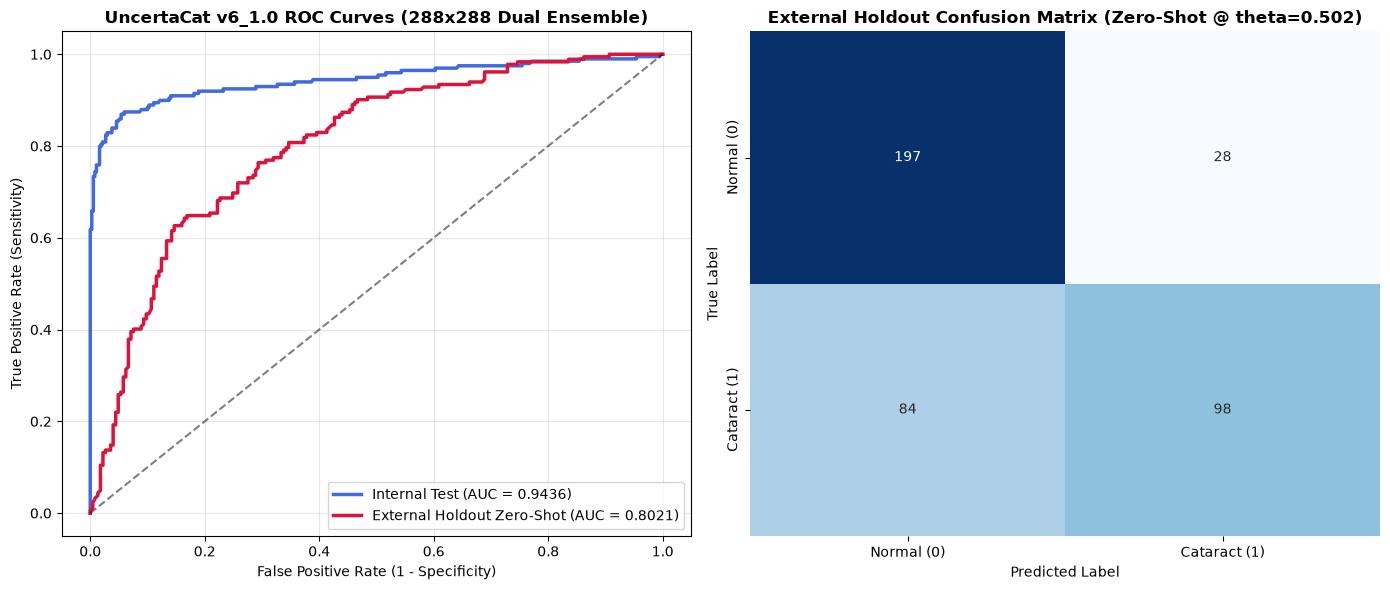

[SUCCESS] Saved figure: c:\Users\umari\Major Project\Major Project New\evaluation_results_v6\roc_and_cm_v6_1.0.png
[CHECK] v6_1.0 Pipeline Concluded Successfully.


In [9]:
# Cell 9: High-Resolution Visualizations & Master Artifact Persistence

# 1. Export Predictions CSVs
df_preds_te = pd.DataFrame({
    'patient_id': densenet_seed_metrics[0]['df_te']['patient_id'],
    'source_dataset': densenet_seed_metrics[0]['df_te']['source_dataset'],
    'true_label': te_y,
    'prob_densenet': dense_te_preds,
    'prob_convnext': conv_te_preds,
    'prob_ensemble_raw': ens_te_raw,
    'prob_ensemble_calibrated': ens_te_calibrated
})
te_csv_path = os.path.join(RESULTS_V6_DIR, 'predictions_internal_test_v6_1.0.csv')
df_preds_te.to_csv(te_csv_path, index=False)

df_preds_ho = pd.DataFrame({
    'patient_id': densenet_seed_metrics[0]['df_ho']['patient_id'],
    'source_dataset': densenet_seed_metrics[0]['df_ho']['source_dataset'],
    'true_label': ho_y,
    'prob_densenet': dense_ho_preds,
    'prob_convnext': conv_ho_preds,
    'prob_ensemble_raw': ens_ho_raw,
    'prob_ensemble_calibrated': ens_ho_calibrated
})
ho_csv_path = os.path.join(RESULTS_V6_DIR, 'predictions_external_holdout_v6_1.0.csv')
df_preds_ho.to_csv(ho_csv_path, index=False)

# 2. Master JSON Manifest
master_v6_1 = {
    'version': 'v6_1.0',
    'paradigm': 'In-Domain Training & Zero-Shot External Evaluation',
    'resolution': 288,
    'architectures': ['DenseNet-121', 'ConvNeXt-Tiny'],
    'seeds': SEEDS,
    'validation_youden_threshold': float(v6_youden_threshold),
    'internal_overall_auc': float(m_ens_te['AUC']),
    'internal_odir_auc': float(auc_odir_ens),
    'internal_eyediseases_auc': float(auc_eye_ens),
    'external_zeroshot_auc': float(m_ens_ho['AUC']),
    'external_zeroshot_sensitivity': float(m_ens_ho['Sensitivity (@ Youden)']),
    'external_zeroshot_specificity': float(m_ens_ho['Specificity (@ Youden)']),
    'densenet_seeds': df_dense_summary.to_dict(orient='records'),
    'convnext_seeds': df_conv_summary.to_dict(orient='records')
}
json_path = os.path.join(RESULTS_V6_DIR, 'results_v6_1.0.json')
with open(json_path, 'w') as f:
    json.dump(master_v6_1, f, indent=4)
print(f"[SUCCESS] Exported v6_1.0 results to: {json_path}")

# 3. Visualizations: ROC and Calibration Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fpr_in, tpr_in, _ = roc_curve(te_y, ens_te_raw)
fpr_ex, tpr_ex, _ = roc_curve(ho_y, ens_ho_raw)

axes[0].plot(fpr_in, tpr_in, label=f'Internal Test (AUC = {m_ens_te["AUC"]:.4f})', color='royalblue', lw=2.5)
axes[0].plot(fpr_ex, tpr_ex, label=f'External Holdout Zero-Shot (AUC = {m_ens_ho["AUC"]:.4f})', color='crimson', lw=2.5)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('UncertaCat v6_1.0 ROC Curves (288x288 Dual Ensemble)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, alpha=0.3)

cm_ho = confusion_matrix(ho_y, (ens_ho_raw >= v6_youden_threshold).astype(int))
sns.heatmap(cm_ho, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Normal (0)', 'Cataract (1)'], yticklabels=['Normal (0)', 'Cataract (1)'])
axes[1].set_title(f'External Holdout Confusion Matrix (Zero-Shot @ theta={v6_youden_threshold:.3f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
fig_path = os.path.join(RESULTS_V6_DIR, 'roc_and_cm_v6_1.0.png')
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"[SUCCESS] Saved figure: {fig_path}")
print("[CHECK] v6_1.0 Pipeline Concluded Successfully.")
